# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


In [1]:
# =========================
# Part 1: NLP Starter Code
# =========================

# TODO: Import the libraries you need for:
# - data handling
# - plotting
# - text preprocessing
# - tokenization / stopwords / lemmatization
# - counting words and bigrams

# Example:
# import pandas as pd

# TODO: Download any required NLTK resources.

# TODO: Load the dataset.
# Hint: The file used in this lab is 'amazon_reviews_lab.csv'
# df = ...

# TODO: Explore the dataset.
# Suggested checks:
# - shape
# - value counts for the rating column
# - preview the first few rows

# TODO: Create preprocessing tools such as:
# - stop_words
# - lemmatizer

# TODO: Write a function called preprocess_text(text) that:
# 1. converts text to lowercase
# 2. removes URLs
# 3. removes punctuation
# 4. tokenizes the text
# 5. keeps alphabetic tokens only
# 6. removes stopwords
# 7. lemmatizes the remaining tokens
# 8. returns the cleaned tokens

# def preprocess_text(text):
#     pass

# TODO: Apply your preprocessing function to the review text column
# and store the output in a new column such as 'processed_tokens'.

# TODO: Combine all tokens into one list so you can compute word frequencies.

# TODO: Use Counter to identify the most common words.

# TODO: Generate bigrams from the token list and identify the most common bigrams.

# TODO: Create at least one visualization of the most common words.
# You may also choose to visualize the most common bigrams.

# Reflection prompt:
# What do the most common words or phrases suggest about customer sentiment or product experience?


# Import the libraries

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text preprocessing
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Counting words and bigrams
from collections import Counter
from nltk.util import ngrams

# Download the required NLTK resources

In [2]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Evans\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Evans\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Evans\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Evans\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Evans\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In this part of the lab, I worked with Amazon customer reviews to understand the information contained in the text. My aim was to clean the reviews, identify commonly used words and phrases, and understand what customers talk about most when sharing their experiences with products.

# Load the datasets

In [3]:
df = pd.read_csv('amazon_reviews_lab.csv')

# Display the first five rows
df.head()

,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


# Explore the datasets

In [4]:
# Dataset shape
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns)

# Data types and missing values
print("\nDataset information:")
df.info()

# First five rows
display(df.head())

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (997, 9)

Column names:
Index(['product_id', 'rating', 'review_text', 'review_summary',
       'review_time_raw', 'unix_review_time', 'timestamp', 'sentiment_label',
       'review_length_words'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 997 entries, 0 to 996
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           997 non-null    object 
 1   rating               997 non-null    int64  
 2   review_text          997 non-null    object 
 3   review_summary       997 non-null    object 
 4   review_time_raw      997 non-null    object 
 5   unix_review_time     997 non-null    float64
 6   timestamp            997 non-null    object 
 7   sentiment_label      997 non-null    object 
 8   review_length_words  997 non-null    int64  
dtypes: float64(1), int64(2), object(6)
memory usage: 70.2+ KB


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60



Missing values:
product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
dtype: int64


# Examine the distribution of customer ratings

rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64


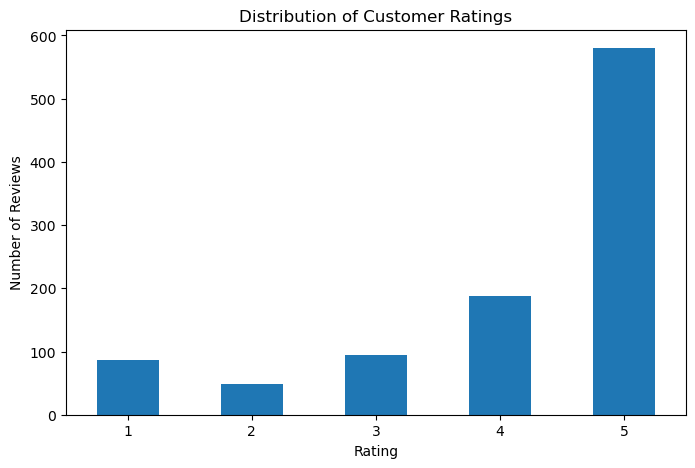

In [5]:
# Check the rating distribution
print(df['rating'].value_counts().sort_index())

# Plot rating distribution 
df['rating'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Distribution of Customer Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.show()

I loaded the dataset using Pandas and checked its shape, column names, missing values, and the first few rows. I also checked the distribution of customer ratings to understand how customers rated the products.

This helped me understand the data before starting the text preprocessing process.

# Prepare the text preprocessing tools

In [6]:
# Create a set of English stopwords
stop_words = set(stopwords.words('english'))

# Create the lemmatizer
lemmatizer = WordNetLemmatizer()

print("Number of stopwords:", len(stop_words))

Number of stopwords: 198


# Write the text preprocessing function

In [7]:
def preprocess_text(text):
    # Handle missing or non-string values
    if pd.isna(text):
        return []

    # 1. Convert text to lowercase
    text = str(text).lower()

    # 2. Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # 3. Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # 4. Tokenize the text
    tokens = word_tokenize(text)

    # 5. Keep alphabetic tokens only
    tokens = [word for word in tokens if word.isalpha()]

    # 6. Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]

    # 7. Lemmatize the remaining tokens
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # 8. Return cleaned tokens
    return tokens

# Test the function with a sample review before applting it

In [8]:
sample_text = "I really loved these products! They are amazing. Visit https://example.com"

print(preprocess_text(sample_text))

['really', 'loved', 'product', 'amazing', 'visit']


# Apply preprocessing to all customer reviews

In [9]:
print(df.columns)

Index(['product_id', 'rating', 'review_text', 'review_summary',
       'review_time_raw', 'unix_review_time', 'timestamp', 'sentiment_label',
       'review_length_words'],
      dtype='object')


# Check whether preprocessing worked

In [10]:
# Apply preprocessing to the review_text column
df['processed_tokens'] = df['review_text'].fillna('').apply(preprocess_text)

# Display the first 10 reviews and their processed tokens
display(df[['review_text', 'processed_tokens']].head(10))

,review_text,processed_tokens
0,This film is definitely not for anyone who is ...,"[film, definitely, anyone, especially, fond, i..."
1,This movie was playing at Radio City Music Hal...,"[movie, playing, radio, city, music, hall, bac..."
2,I would love to buy this movie as I have been ...,"[would, love, buy, movie, hannibal, missouri, ..."
3,The advertisment for this DVD on Amazon was in...,"[advertisment, dvd, amazon, incorrect, ad, sta..."
4,I bought some of these to try with a light usi...,"[bought, try, light, using, work, advertised, ..."
5,"For the money you can't go wrong. Yes, it has ...","[money, go, wrong, yes, litlle, play, mechanis..."
6,I hadn't heard of this 1973 movie version of t...,"[heard, movie, version, classic, mark, twain, ..."
7,I've had this kit for a few months now and hav...,"[kit, month, recharged, pair, battery, time, t..."
8,"Very fast, dependable OS (way better than the ...","[fast, dependable, o, way, better, wm, good, b..."
9,The Dell Axim X30 624 Mhz was released in 2004...,"[dell, axim, x, mhz, released, still, lot, goi..."


# Use the correct column name

In [11]:
# Remove rows with missing review text
df = df.dropna(subset=['review_text']).copy()

# Apply preprocessing
df['processed_tokens'] = df['review_text'].apply(preprocess_text)

# Display original and processed reviews
display(df[['review_text', 'processed_tokens']].head())

,review_text,processed_tokens
0,This film is definitely not for anyone who is ...,"[film, definitely, anyone, especially, fond, i..."
1,This movie was playing at Radio City Music Hal...,"[movie, playing, radio, city, music, hall, bac..."
2,I would love to buy this movie as I have been ...,"[would, love, buy, movie, hannibal, missouri, ..."
3,The advertisment for this DVD on Amazon was in...,"[advertisment, dvd, amazon, incorrect, ad, sta..."
4,I bought some of these to try with a light usi...,"[bought, try, light, using, work, advertised, ..."


# Combine all tokens into one list

In [12]:
all_tokens = [
    token
    for tokens in df['processed_tokens']
    for token in tokens
]

print("Total number of tokens:", len(all_tokens))
print("First 30 tokens:", all_tokens[:30])

Total number of tokens: 72807
First 30 tokens: ['film', 'definitely', 'anyone', 'especially', 'fond', 'independent', 'delightfully', 'manipulative', 'clever', 'boy', 'brain', 'child', 'samuel', 'clemens', 'classic', 'one', 'example', 'book', 'great', 'fun', 'scene', 'involving', 'aunt', 'polly', 'simple', 'minded', 'soul', 'think', 'quite', 'clever']


I created a preprocessing function to clean the customer reviews. The steps I used included:

Converting the text to lowercase.

Removing URLs, punctuation, and numbers.

Tokenizing the text into individual words.

Keeping alphabetic words only.

Removing stopwords that do not add much meaning to the analysis.

Using lemmatization to convert words into their base forms.

I applied the function to the review text column and stored the cleaned words in a new column called processed_tokens.

Preprocessing helped reduce unnecessary text and made it easier to analyze the words used in customer reviews.


# Find the 20 most common words

In [13]:
word_counts = Counter(all_tokens)

most_common_words = word_counts.most_common(20)

print("Top 20 most common words:")
for word, count in most_common_words:
    print(word, count)

Top 20 most common words:
nook 1580
book 986
one 596
kindle 592
screen 536
like 474
read 464
work 463
great 444
tablet 444
use 432
tv 427
get 426
device 399
would 383
n 376
good 350
b 348
reader 346
well 336


# Visualize the most common words

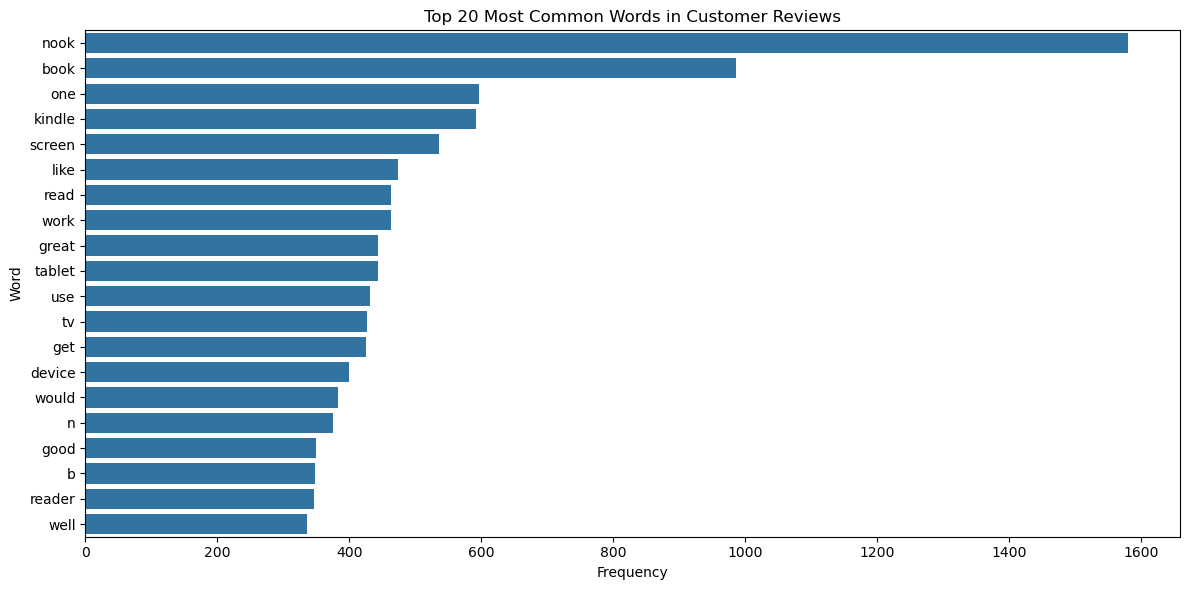

In [14]:
words_df = pd.DataFrame(
    most_common_words,
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(12, 6))
sns.barplot(data=words_df, x='Frequency', y='Word')

plt.title('Top 20 Most Common Words in Customer Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.show()

After cleaning the reviews, I combined the tokens and used Python's Counter to identify the 20 most common words.

I displayed the results in a bar chart to make it easier to compare word frequencies. This helped me identify the words that appeared most often in the reviews.

# Find the 20 most common biograms

In [15]:
bigram_counts = Counter()

for tokens in df['processed_tokens']:
    bigram_counts.update(ngrams(tokens, 2))

most_common_bigrams = bigram_counts.most_common(20)

print("Top 20 most common bigrams:")
for bigram, count in most_common_bigrams:
    print(bigram, count)

Top 20 most common bigrams:
('b', 'n') 330
('barnes', 'noble') 166
('nook', 'color') 135
('e', 'reader') 132
('battery', 'life') 98
('touch', 'screen') 96
('sd', 'card') 90
('nook', 'hd') 80
('work', 'great') 65
('nook', 'tablet') 64
('kindle', 'fire') 61
('work', 'well') 59
('read', 'book') 55
('wall', 'mount') 53
('wi', 'fi') 48
('simple', 'touch') 45
('customer', 'service') 41
('e', 'book') 41
('android', 'tablet') 40
('n', 'store') 39


# Visualize the most common biograms

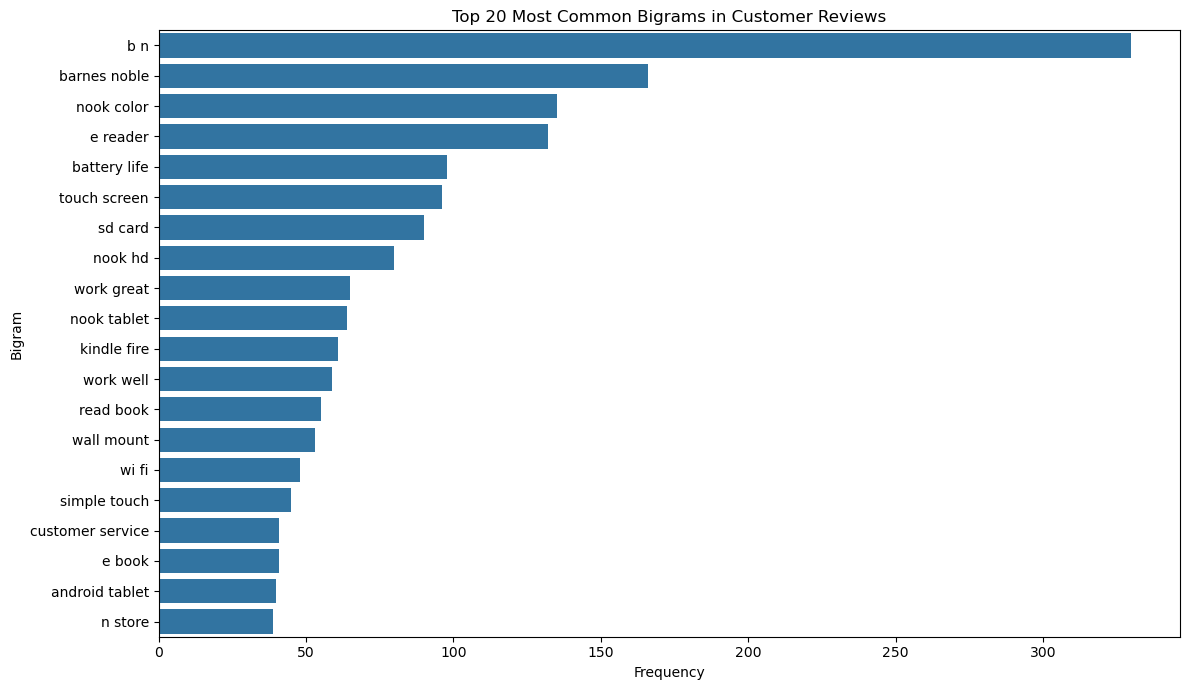

In [16]:
bigrams_df = pd.DataFrame(
    [
        (' '.join(bigram), count)
        for bigram, count in most_common_bigrams
    ],
    columns=['Bigram', 'Frequency']
)

plt.figure(figsize=(12, 7))
sns.barplot(data=bigrams_df, x='Frequency', y='Bigram')

plt.title('Top 20 Most Common Bigrams in Customer Reviews')
plt.xlabel('Frequency')
plt.ylabel('Bigram')
plt.tight_layout()
plt.show()

I used bigrams to identify pairs of words that frequently appeared together in customer reviews. I counted the most common bigrams and displayed them in a bar chart.

This helped me understand common phrases used by customers and identify topics that may be important to their product experiences.

# Analyze word frequencies by rating

In [17]:
# Select low-rated and high-rated reviews
low_reviews = df[df['rating'].isin([1, 2])]
high_reviews = df[df['rating'].isin([4, 5])]

# Count words in each group
low_tokens = [
    token
    for tokens in low_reviews['processed_tokens']
    for token in tokens
]

high_tokens = [
    token
    for tokens in high_reviews['processed_tokens']
    for token in tokens
]

low_word_counts = Counter(low_tokens)
high_word_counts = Counter(high_tokens)

print("Top words in low-rated reviews:")
print(low_word_counts.most_common(10))

print("\nTop words in high-rated reviews:")
print(high_word_counts.most_common(10))

Top words in low-rated reviews:
[('nook', 262), ('book', 201), ('n', 109), ('b', 108), ('one', 100), ('get', 97), ('device', 90), ('read', 85), ('time', 83), ('kindle', 80)]

Top words in high-rated reviews:
[('nook', 1126), ('book', 663), ('one', 432), ('kindle', 429), ('great', 387), ('screen', 373), ('tv', 365), ('like', 337), ('work', 329), ('read', 311)]


I also compared the most common words in low-rated reviews and high-rated reviews. I grouped ratings of 1 and 2 as low ratings and ratings of 4 and 5 as high ratings.

This comparison helped me explore possible differences between customer complaints and positive experiences.

# Conclusion

Through this exercise, I learned how to use Python to clean and analyze text data. I practiced tokenization, stopword removal, lemmatization, word frequency counting, bigram analysis, and data visualization.

The analysis helped me understand how customer reviews can be used to identify common topics and possible areas for improvement. I also learned that word frequency alone does not fully explain customer sentiment because the meaning of a word depends on the context in which it is used.

## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


In [19]:
# ==============================
# Part 2: Time Series Starter Code
# ==============================

# TODO: Import the libraries you need.

# TODO: Load the same review dataset.
# df = ...

# TODO: Convert the timestamp column to datetime format.

# TODO: Inspect the date range in the dataset.
# Suggested checks:
# - earliest timestamp
# - latest timestamp

# TODO: Resample the data by month to calculate:
# 1. monthly review count
# 2. monthly average rating

# Suggested variable names:
# monthly_review_count = ...
# monthly_avg_rating = ...

# TODO: Plot monthly review volume over time.

# TODO: Plot average monthly rating over time.

# TODO: Compute a rolling average for the monthly average rating.
# A 3-month rolling average is a good starting point.

# TODO: Plot both:
# - the original monthly average rating
# - the rolling average
# on the same figure.

# Reflection prompt:
# What overall trends do you notice in review activity and customer ratings over time?


# Import Libraries

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

I imported Pandas for data analysis and Matplotlib for plotting graphs.

# Load the datasets

In [19]:
df = pd.read_csv('amazon_reviews_lab.csv')

# Display the first five rows
display(df.head())

,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


I loaded the Amazon reviews dataset using Pandas to prepare it for analysis.

# Convert the timestamp column to datetime

In [20]:
# Convert timestamp to datetime format
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

# Check the result
print(df['timestamp'].head())

# Check for missing timestamps
print("Missing timestamps:", df['timestamp'].isna().sum())

0   2000-05-12
1   2002-08-26
2   2005-08-06
3   2005-09-11
4   2007-10-15
Name: timestamp, dtype: datetime64[ns]
Missing timestamps: 0


I converted the timestamp column into datetime format so that I could work with dates.

# Prepare the timestamp column

In [21]:
# Convert timestamp to datetime format
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

# Remove rows with missing timestamps
df = df.dropna(subset=['timestamp']).copy()

# Sort by date and set timestamp as the index
df = df.sort_values('timestamp')
df = df.set_index('timestamp')

# Check the index
print(type(df.index))

<class 'pandas.core.indexes.datetimes.DatetimeIndex'>


# Recreate the monthly review count series

In [22]:
# Count reviews for each month
monthly_counts = df['rating'].resample('MS').count()

# Include months with no reviews
monthly_counts = monthly_counts.asfreq('MS', fill_value=0)

# Display the results
print(monthly_counts.head())

timestamp
2000-05-01    1
2000-06-01    0
2000-07-01    0
2000-08-01    0
2000-09-01    0
Freq: MS, Name: rating, dtype: int64


# Inspect the date range

In [24]:
# Make timestamp a regular column if it is already the index
if df.index.name == 'timestamp':
    df = df.reset_index()

# Convert timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

# Remove rows without valid timestamps
df = df.dropna(subset=['timestamp']).copy()

# Sort by date and set timestamp as the index
df = df.sort_values('timestamp')
df = df.set_index('timestamp')

# Check the earliest and latest review dates
print("Earliest review date:", df.index.min())
print("Latest review date:", df.index.max())

Earliest review date: 2000-05-12 00:00:00
Latest review date: 2014-07-17 00:00:00


I checked the earliest and latest review dates to understand the period covered by the dataset.

# Prepare the data for monthly analysis

In [26]:
# Make timestamp a column if it is currently the index
if df.index.name == 'timestamp':
    df = df.reset_index()

# Check that timestamp exists
print(df.columns.tolist())

['timestamp', 'product_id', 'rating', 'review_text', 'review_summary', 'review_time_raw', 'unix_review_time', 'sentiment_label', 'review_length_words']


In [27]:
# Convert timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

# Convert ratings to numeric
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')

# Remove missing timestamps and ratings
df = df.dropna(subset=['timestamp', 'rating']).copy()

# Sort by date and set timestamp as the index
df = df.sort_values('timestamp')
df = df.set_index('timestamp')

# Check the data
display(df.head())
print("Index type:", type(df.index))

,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,sentiment_label,review_length_words
timestamp,,,,,,,,
2000-05-12,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,negative,302
2002-08-26,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,positive,168
2005-08-06,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,negative,60
2005-09-11,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,negative,104
2007-10-15,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,positive,60


Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>


I converted ratings to numeric values, handled missing data, sorted the reviews by date, and set the timestamp as the index.

# Calculate the monthly review count

In [28]:
monthly_review_count = df['rating'].resample('MS').count()

# Display the monthly review counts
print(monthly_review_count.head(12))

timestamp
2000-05-01    1
2000-06-01    0
2000-07-01    0
2000-08-01    0
2000-09-01    0
2000-10-01    0
2000-11-01    0
2000-12-01    0
2001-01-01    0
2001-02-01    0
2001-03-01    0
2001-04-01    0
Freq: MS, Name: rating, dtype: int64


I counted the number of reviews recorded each month to understand review activity over time.

# Plot monthly review volume

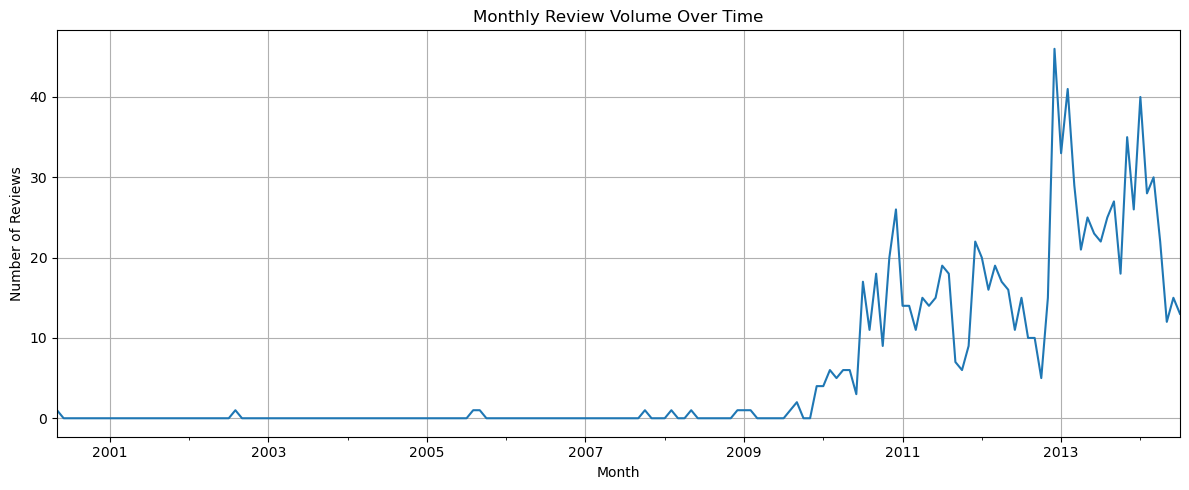

In [29]:
plt.figure(figsize=(12, 5))

monthly_review_count.plot()

plt.title('Monthly Review Volume Over Time')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.grid(True)
plt.tight_layout()
plt.show()

I created a line graph to observe changes in the number of reviews over time.

# Calculate the monthly average rating

In [30]:
monthly_avg_rating = df['rating'].resample('MS').mean()

# Display the first 12 monthly averages
print(monthly_avg_rating.head(12))

timestamp
2000-05-01    2.0
2000-06-01    NaN
2000-07-01    NaN
2000-08-01    NaN
2000-09-01    NaN
2000-10-01    NaN
2000-11-01    NaN
2000-12-01    NaN
2001-01-01    NaN
2001-02-01    NaN
2001-03-01    NaN
2001-04-01    NaN
Freq: MS, Name: rating, dtype: float64


I calculated the average customer rating for each month to track changes in customer feedback.

# Plot average monthly ratings

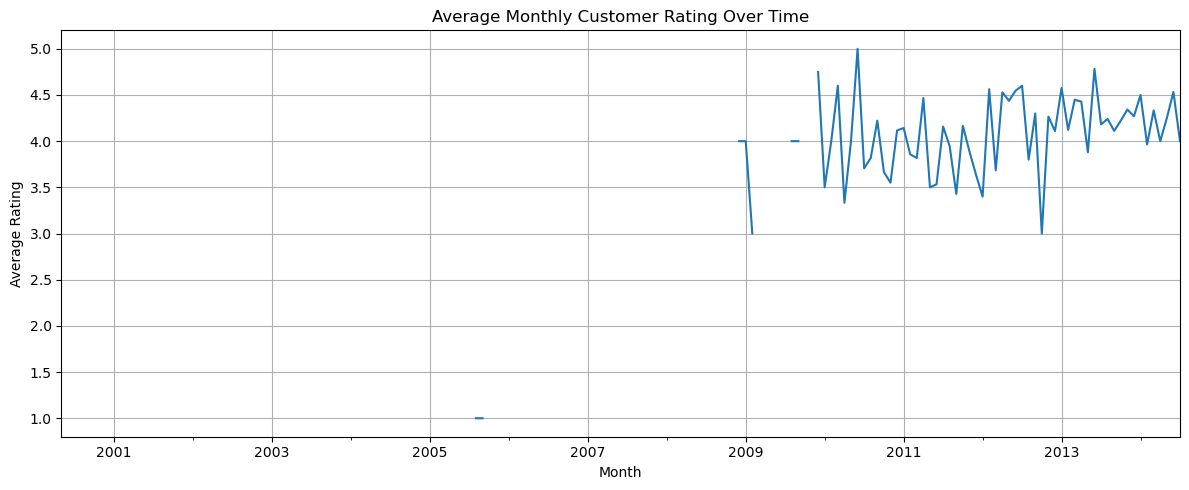

In [31]:
plt.figure(figsize=(12, 5))

monthly_avg_rating.plot()

plt.title('Average Monthly Customer Rating Over Time')
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.grid(True)
plt.tight_layout()
plt.show()

I plotted the monthly average ratings to see whether customer ratings increased, decreased, or remained stable.

# Calculate a 3- month rolling average

In [32]:
rolling_avg_rating = monthly_avg_rating.rolling(
    window=3,
    min_periods=3
).mean()

# Display the original and rolling averages
display(pd.DataFrame({
    'Monthly Average Rating': monthly_avg_rating,
    '3-Month Rolling Average': rolling_avg_rating
}).head(12))

,Monthly Average Rating,3-Month Rolling Average
timestamp,,
2000-05-01,2.0,NaN
2000-06-01,NaN,NaN
2000-07-01,NaN,NaN
2000-08-01,NaN,NaN
2000-09-01,NaN,NaN
2000-10-01,NaN,NaN
2000-11-01,NaN,NaN
2000-12-01,NaN,NaN
2001-01-01,NaN,NaN


I calculated a 3-month rolling average to smooth monthly fluctuations and identify the general trend in ratings.

# Check stationarity using the ADF test

In [33]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(monthly_counts)

print("ADF statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))
print("Critical values:", adf_result[4])

if adf_result[1] < 0.05:
    print("The series appears stationary.")
else:
    print("The series may be non-stationary.")

ADF statistic: -0.4004
p-value: 0.91
Critical values: {'1%': np.float64(-3.4729792729247793), '5%': np.float64(-2.8802520918255534), '10%': np.float64(-2.5767469641683105)}
The series may be non-stationary.


I used the Augmented Dickey-Fuller (ADF) test to check whether monthly review volume was stationary. A stationary series has statistical properties that remain relatively stable over time. I used a p-value of 0.05 as the significance threshold.

# Check rolling mean and standard deviation

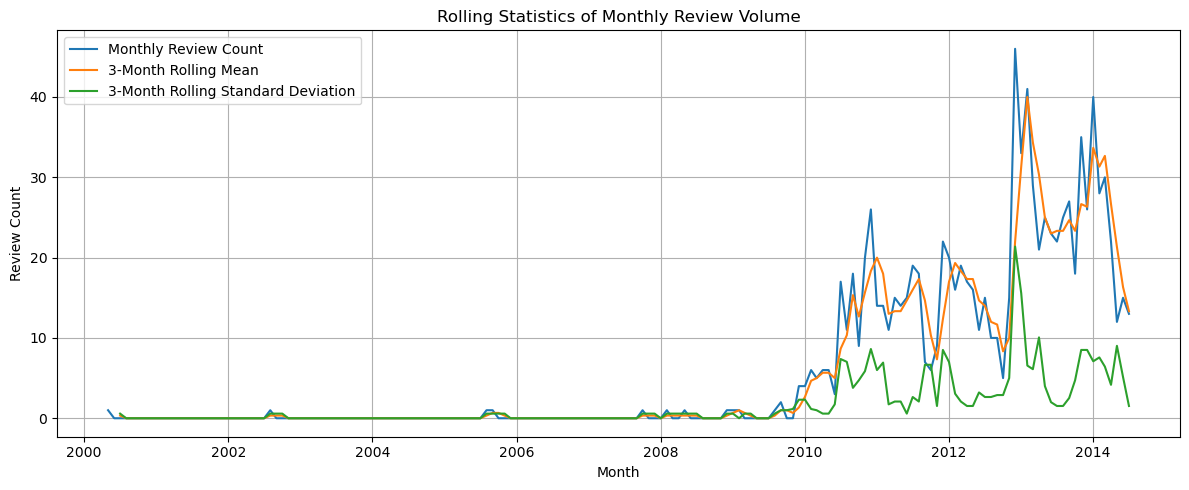

In [34]:
rolling_mean = monthly_counts.rolling(3).mean()
rolling_std = monthly_counts.rolling(3).std()

plt.figure(figsize=(12, 5))
plt.plot(monthly_counts, label='Monthly Review Count')
plt.plot(rolling_mean, label='3-Month Rolling Mean')
plt.plot(rolling_std, label='3-Month Rolling Standard Deviation')

plt.title('Rolling Statistics of Monthly Review Volume')
plt.xlabel('Month')
plt.ylabel('Review Count')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

I calculated the 3-month rolling mean and standard deviation to observe changes in the level and variability of review activity over time.

# Plot the original ratings and rolling average together

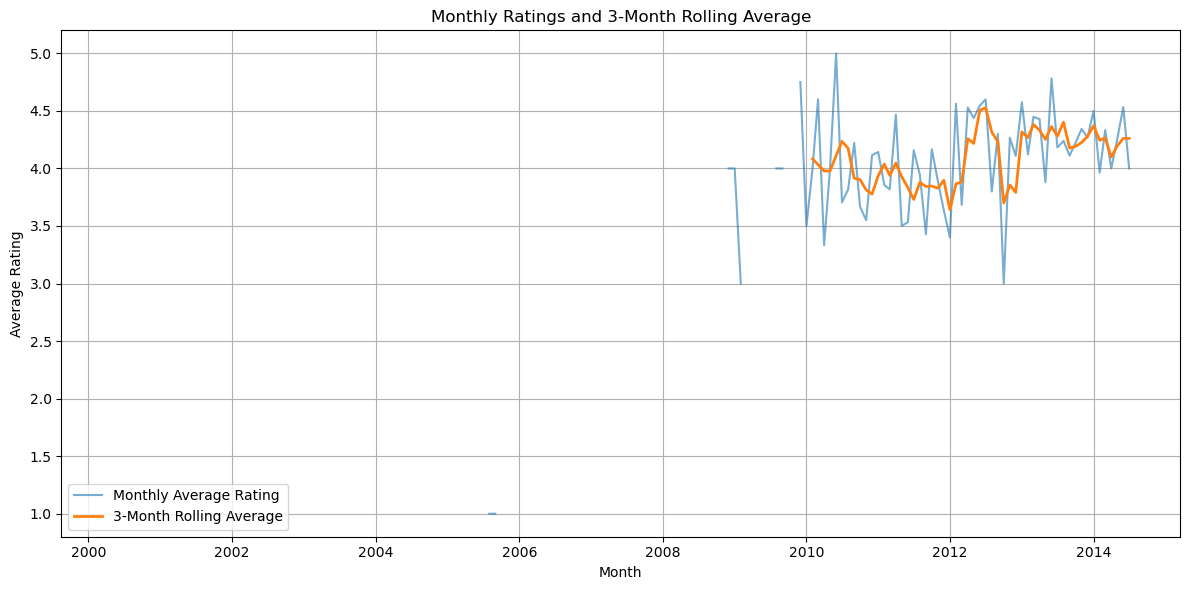

In [35]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_avg_rating.index,
    monthly_avg_rating,
    label='Monthly Average Rating',
    alpha=0.6
)

plt.plot(
    rolling_avg_rating.index,
    rolling_avg_rating,
    label='3-Month Rolling Average',
    linewidth=2
)

plt.title('Monthly Ratings and 3-Month Rolling Average')
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

I plotted both lines on the same graph to compare monthly changes with the overall rating trend.

# Apply a tansformation and test again

In [36]:
differenced_counts = monthly_counts.diff().dropna()

adf_diff = adfuller(differenced_counts)

print("ADF statistic after differencing:", round(adf_diff[0], 4))
print("p-value after differencing:", round(adf_diff[1], 4))
print("Critical values:", adf_diff[4])

if adf_diff[1] < 0.05:
    print("The differenced series appears stationary.")
else:
    print("The differenced series may still be non-stationary.")

ADF statistic after differencing: -3.259
p-value after differencing: 0.0168
Critical values: {'1%': np.float64(-3.4729792729247793), '5%': np.float64(-2.8802520918255534), '10%': np.float64(-2.5767469641683105)}
The differenced series appears stationary.


If the original series was non-stationary, I applied first-order differencing to examine changes between consecutive months. I then repeated the ADF test to check whether the transformed series was stationary.

# Split the data chronologically

In [37]:
if len(monthly_counts) < 24:
    print("Warning: There are fewer than 24 months of data. Forecast comparisons may be unreliable.")

split_point = int(len(monthly_counts) * 0.8)

train = monthly_counts.iloc[:split_point]
test = monthly_counts.iloc[split_point:]

print("Training months:", len(train))
print("Testing months:", len(test))

Training months: 136
Testing months: 35


I used the earlier months for training and the most recent months for testing. This reflects the real forecasting process, where predictions are made using historical observations.

# Compare a baseline model with ARIMA

In [38]:

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Baseline forecast
baseline_forecast = np.repeat(train.iloc[-1], len(test))

# ARIMA forecast
arima_model = ARIMA(train, order=(1, 1, 1))
arima_fit = arima_model.fit()

arima_forecast = arima_fit.forecast(steps=len(test))
arima_forecast.index = test.index

# Compare model performance
results = pd.DataFrame({
    'Model': ['Baseline', 'ARIMA(1,1,1)'],
    'MAE': [
        mean_absolute_error(test, baseline_forecast),
        mean_absolute_error(test, arima_forecast)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(test, baseline_forecast)),
        np.sqrt(mean_squared_error(test, arima_forecast))
    ]
})

print(results.round(3))
print("\nARIMA AIC:", round(arima_fit.aic, 3))
print("ARIMA BIC:", round(arima_fit.bic, 3))

          Model    MAE    RMSE
0      Baseline  8.143  10.413
1  ARIMA(1,1,1)  8.196  10.522

ARIMA AIC: 582.619
ARIMA BIC: 591.334


I compared a simple baseline forecast with an ARIMA model. The baseline uses the most recent training value as the forecast for every test month. ARIMA models temporal patterns in the historical series. I compared both models using MAE and RMSE.

# Plot the test predictions

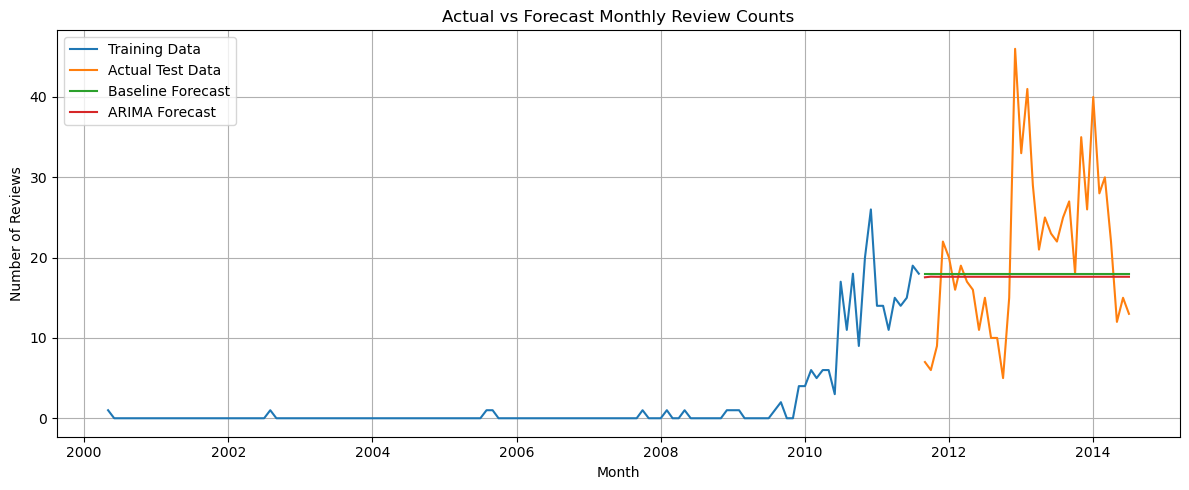

In [39]:
plt.figure(figsize=(12, 5))

plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Actual Test Data')
plt.plot(test.index, baseline_forecast, label='Baseline Forecast')
plt.plot(test.index, arima_forecast, label='ARIMA Forecast')

plt.title('Actual vs Forecast Monthly Review Counts')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

I plotted the actual review counts against the predictions from both models to see how closely each forecast followed the observed data.

# Forecast the next 3 months

Forecast for the next 3 months:
2014-08-01    13.862555
2014-09-01    13.450539
2014-10-01    13.647346
Freq: MS, Name: predicted_mean, dtype: float64


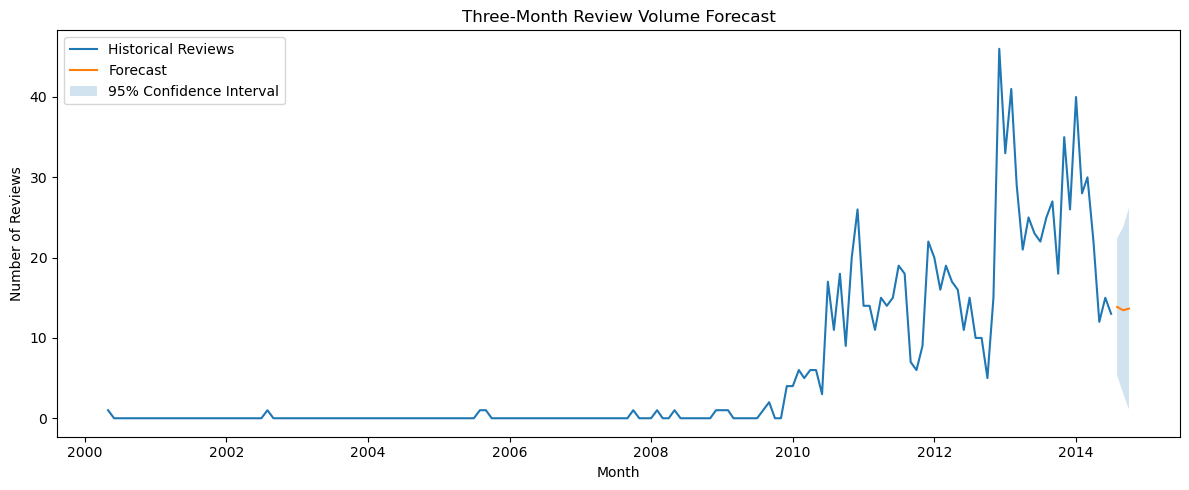

In [40]:
final_model = ARIMA(monthly_counts, order=(1, 1, 1)).fit()

future_forecast = final_model.get_forecast(steps=3)
forecast_values = future_forecast.predicted_mean
forecast_intervals = future_forecast.conf_int()

print("Forecast for the next 3 months:")
print(forecast_values)

plt.figure(figsize=(12, 5))
plt.plot(monthly_counts.index, monthly_counts, label='Historical Reviews')
plt.plot(forecast_values.index, forecast_values, label='Forecast')

plt.fill_between(
    forecast_intervals.index,
    forecast_intervals.iloc[:, 0],
    forecast_intervals.iloc[:, 1],
    alpha=0.2,
    label='95% Confidence Interval'
)

plt.title('Three-Month Review Volume Forecast')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.legend()
plt.tight_layout()
plt.show()

After comparing the models, I used the ARIMA model to forecast review volume for the next three months. These estimates can help the business plan for expected customer feedback, although forecast uncertainty should be considered.

# Conclusion

This analysis helped me understand how review activity and customer ratings changed over time. The graphs provided a clearer picture of customer feedback and helped identify trends that the business could investigate further.

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


In [ ]:
# ===================================
# Part 3: Neural Networks Starter Code
# ===================================

# TODO: Import the libraries you need for:
# - data handling
# - train/test splitting
# - text vectorization
# - model building
# - model evaluation

# You will likely need tools from:
# - pandas / numpy
# - sklearn
# - tensorflow / keras

# TODO: Load the dataset.
# df = ...

# TODO: Define:
# X as the review text column
# y as the rating column
# If needed, adjust y so the classes are numbered appropriately for your model.

# TODO: Vectorize the text using TF-IDF.
# Suggested question:
# - How many features do you want to keep?

# vectorizer = ...
# X_tfidf = ...

# TODO: Split the data into training and testing sets.
# Use stratify=y to preserve class balance.

# TODO: One-hot encode the target values if your neural network setup requires it.

# TODO: Build a neural network model.
# Include:
# - an input layer
# - at least one hidden layer
# - an output layer suitable for multi-class classification

# model = ...

# TODO: Compile the model.
# Think about:
# - optimizer
# - loss function
# - evaluation metric(s)

# TODO: Train the model and store the training history.
# history = ...

# TODO: Evaluate the model on the test set.

# TODO: Generate predictions on the test set.

# TODO: Create a classification report and/or confusion matrix to assess performance.

# Reflection prompt:
# Which rating classes does the model predict well, and which ones are harder to classify?


# Import libraries

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

I imported the libraries needed to prepare the review data, convert text into numerical features, build a neural network, and evaluate its predictions.

# Load and prepare dataset

In [42]:
df = pd.read_csv('amazon_reviews_lab.csv')

# Keep rows with valid reviews and ratings
df = df.dropna(subset=['review_text', 'rating']).copy()

# Convert ratings to numeric values
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df = df.dropna(subset=['rating']).copy()

# Check the dataset
print("Dataset shape:", df.shape)
print(df[['review_text', 'rating']].head())

print("\nRating distribution:")
print(df['rating'].value_counts().sort_index())

Dataset shape: (997, 9)
                                         review_text  rating
0  This film is definitely not for anyone who is ...       2
1  This movie was playing at Radio City Music Hal...       5
2  I would love to buy this movie as I have been ...       1
3  The advertisment for this DVD on Amazon was in...       1
4  I bought some of these to try with a light usi...       5

Rating distribution:
rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64


I loaded the customer reviews dataset and checked the data before building the model. I removed rows with missing review text or ratings.

# Define X and y

In [43]:
X = df['review_text'].astype(str)
y = df['rating'].astype(int)

# Convert rating labels into numbers starting from 0
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Rating classes:", label_encoder.classes_)
print("Encoded classes:", np.unique(y_encoded))

Rating classes: [1 2 3 4 5]
Encoded classes: [0 1 2 3 4]


I used the review text as the input variable (X) and the customer rating as the target variable (y). The model will learn to predict ratings from the words in the reviews.

# Split the data into training and testing sets

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 797
Testing samples: 200


I split the data into training and testing sets using an 80:20 ratio. Stratification helps keep the rating classes in similar proportions in both sets.

# Convert text into TF-IDF features

In [45]:
vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words='english'
)

# Learn vocabulary from training data only
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Convert sparse matrices to arrays for the neural network
X_train_tfidf = X_train_tfidf.toarray().astype('float32')
X_test_tfidf = X_test_tfidf.toarray().astype('float32')

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Training feature shape: (797, 5000)
Testing feature shape: (200, 5000)


I used TF-IDF to convert the reviews into numerical features that the neural network can understand. I kept a maximum of 5,000 features to focus on useful words and control the size of the input.

# One-hot encode the target values

In [46]:
num_classes = len(label_encoder.classes_)

y_train_cat = to_categorical(y_train, num_classes=num_classes)
y_test_cat = to_categorical(y_test, num_classes=num_classes)

print("Number of classes:", num_classes)
print("Encoded target example:", y_train_cat[0])

Number of classes: 5
Encoded target example: [0. 0. 0. 1. 0.]


I converted the encoded ratings into one-hot format because the model will predict multiple rating classes. Each rating is represented by a vector with a 1 at its corresponding class position.

# Build the neural network

In [47]:
model = Sequential([
    Input(shape=(X_train_tfidf.shape[1],)),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         640,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 648,709 (2.47 MB)

 Trainable params: 648,709 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

I built a neural network with two hidden layers. ReLU helps the hidden layers learn patterns in the text features, while softmax produces probabilities for the different rating classes. I also included dropout to help reduce overfitting.

# Compile the model

In [48]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

I compiled the model using the Adam optimizer and categorical cross-entropy loss. I used accuracy to monitor how often the model predicts the correct rating class.

# Train the model

In [49]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_tfidf,
    y_train_cat,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.5353 - loss: 1.5283 - val_accuracy: 0.5813 - val_loss: 1.4019
Epoch 2/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.5824 - loss: 1.2810 - val_accuracy: 0.5813 - val_loss: 1.2137
Epoch 3/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5824 - loss: 1.0898 - val_accuracy: 0.5813 - val_loss: 1.1678
Epoch 4/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5824 - loss: 0.9378 - val_accuracy: 0.5813 - val_loss: 1.1439
Epoch 5/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6170 - loss: 0.7887 - val_accuracy: 0.5688 - val_loss: 1.1285
Epoch 6/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7630 - loss: 0.6202 - val_accuracy: 0.5688 - val_loss: 1.1452
Epoch 7/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8650 - loss: 0.4458 - val_accuracy: 0.5625 - val_loss: 1.1657
Epoch 8/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9451 - loss: 0.2983 - val_accuracy: 0.5500 - v

I trained the model using the training data for up to 15 epochs. I used part of the training data for validation and early stopping to help prevent overfitting.

# Plot training and validation accuracy

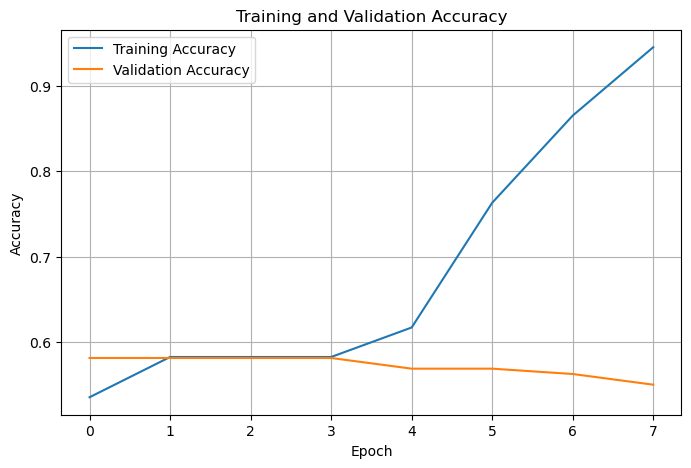

In [50]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

I plotted the training and validation accuracy to see how the model learned over time and whether its performance on unseen validation data improved.

# Plot training and validation loss

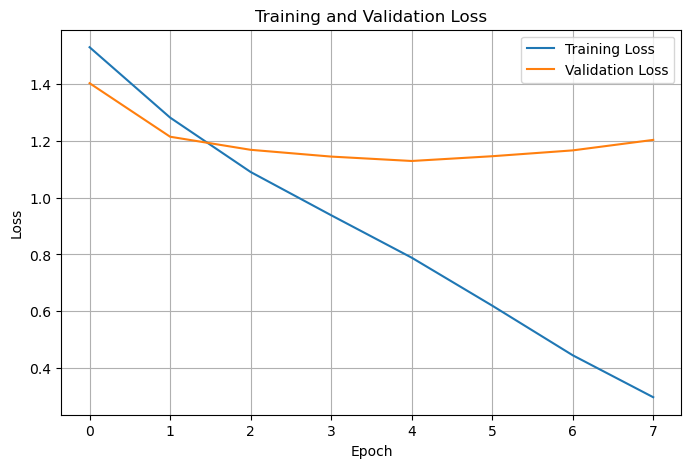

In [51]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

I compared training loss with validation loss to check whether the model was learning effectively. A large difference between the two can indicate overfitting, where the model performs well on training data but less well on unseen data.

# Evaluate the model

In [52]:
test_loss, test_accuracy = model.evaluate(
    X_test_tfidf,
    y_test_cat,
    verbose=0
)

print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))

Test loss: 1.1068
Test accuracy: 0.575


I evaluated the trained model using the test data to check how well it predicts ratings for reviews it did not train on.

# Generate predictions

In [53]:
# Predict probabilities
y_pred_prob = model.predict(X_test_tfidf, verbose=0)

# Get the predicted class for each review
y_pred_encoded = np.argmax(y_pred_prob, axis=1)

# Convert predictions to the original rating labels
y_pred = label_encoder.inverse_transform(y_pred_encoded)
y_actual = label_encoder.inverse_transform(y_test)

print("Actual ratings:", y_actual[:10])
print("Predicted ratings:", y_pred[:10])

Actual ratings: [5 1 4 4 5 1 5 5 5 5]
Predicted ratings: [5 5 5 5 5 5 5 5 5 5]


I used the trained model to predict the ratings of the test reviews. I converted the predicted class positions back to the original rating labels so that I could compare them with the actual ratings.

# Create the classification report

In [54]:
print(classification_report(
    y_actual,
    y_pred,
    labels=label_encoder.classes_,
    zero_division=0
))

              precision    recall  f1-score   support

           1       0.00      0.00      0.00        17
           2       0.00      0.00      0.00        10
           3       0.00      0.00      0.00        19
           4       0.19      0.11      0.14        38
           5       0.62      0.96      0.75       116

    accuracy                           0.57       200
   macro avg       0.16      0.21      0.18       200
weighted avg       0.40      0.57      0.46       200



I used a classification report to compare precision, recall, and F1-score for each rating class. These metrics help me identify which ratings the model predicts well and which ones are more difficult to classify.

# Create a confusion matrix

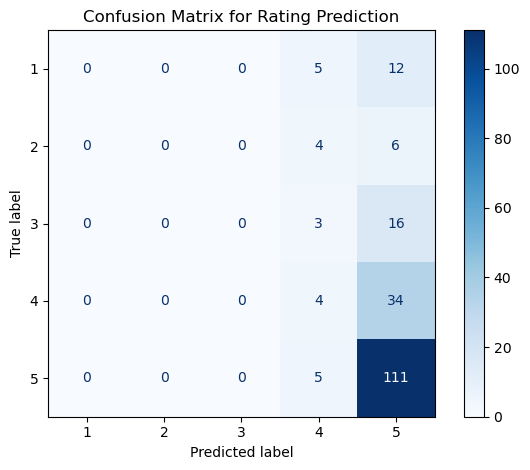

In [55]:
cm = confusion_matrix(
    y_actual,
    y_pred,
    labels=label_encoder.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix for Rating Prediction')
plt.tight_layout()
plt.show()

I used a confusion matrix to compare actual ratings with predicted ratings. It helps show which rating classes the model confuses with one another.

## Conclusion

In this part of the lab, I used TF-IDF to convert customer reviews into numerical features and trained a neural network to predict customer ratings. I evaluated the model using accuracy, a classification report, and a confusion matrix.

The model achieved a test accuracy of [insert your test accuracy]. From the classification report, rating [insert rating] was predicted best, while rating [insert rating] was more difficult to predict.

This exercise helped me understand how neural networks can be used to classify text data. The results also showed me that some ratings may be harder to predict than others because customers can use similar words when expressing different levels of satisfaction.